# Moreira and Muir (2017) replication

This notebook consolidates the available Moreira and Muir (2017) replication in the paper's presentation order. The selected published benchmarks shown below are transcribed from Tables I–III of Moreira, A., and T. Muir (2017), ‘Volatility-Managed Portfolios,’ *The Journal of Finance* 72(4), 1611–1644, https://doi.org/10.1111/jofi.12513. They are included solely to evaluate the replication; the paper and its table layouts are not reproduced.

Monthly realized variance is the sum of demeaned squared daily factor returns. The return in month $t$ is multiplied by $c/RV_{t-1}$, where $c$ is one fixed positive constant chosen to match the original factor's volatility through the replication endpoint; no month-$t$ information enters its weight. The primary sample ends in April 2015, inferred from Table I observation counts. The scope is Figures 1–3, Table I's available factors and controls, the available Table II Panel A opportunity sets, and Table III; SMB and FF5 spanning are labelled extensions. Monthly inference follows the project convention of Newey–West HAC standard errors with 12 lags, whereas the paper reports heteroskedasticity-only standard errors. The comparison tables therefore validate point estimates rather than claiming identical t-statistics.

In [1]:
# 0. Libraries and project modules
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from config import (
    ANALYSIS_END, FACTORS, HAC_LAGS, MANAGED_FACTORS, MVE_TABLE,
    REPLICATION_MVE_SETS, SPANNING_TABLE, TABLES,
)
from data import load_factor_returns, load_processed_panel
from descriptive_statistics import market_volatility_sorts
from mean_variance import replicate_mve_volatility_timing
from plots import plot_market_cumulative_performance, plot_market_volatility_sorts, plot_realized_volatility
from spanning import run_recession_beta_tests, run_spanning_tests

In [2]:
# 1. Load the validated replication sample
daily, _ = load_factor_returns()
panel = load_processed_panel(MANAGED_FACTORS, FACTORS, ANALYSIS_END)
print(f'Sample: {panel.date.min().date()} to {panel.date.max().date()} | rows: {len(panel)}')

Sample: 1926-07-31 to 2015-04-30 | rows: 1066


## 2. Figure 1: market outcomes by lagged-volatility quintile

,volatility_bucket,count,mean,std,var,mean_annual_pct,volatility_annual_pct,mean_divided_by_variance,recession_probability
0,1,213,0.006,0.030,0.001,6.826,10.390,6.324,0.103
1,2,213,0.008,0.040,0.002,10.079,13.702,5.368,0.085
2,3,213,0.003,0.041,0.002,3.609,14.066,1.824,0.146
3,4,213,0.009,0.051,0.003,10.619,17.747,3.372,0.169
4,5,213,0.007,0.089,0.008,8.011,30.720,0.849,0.432


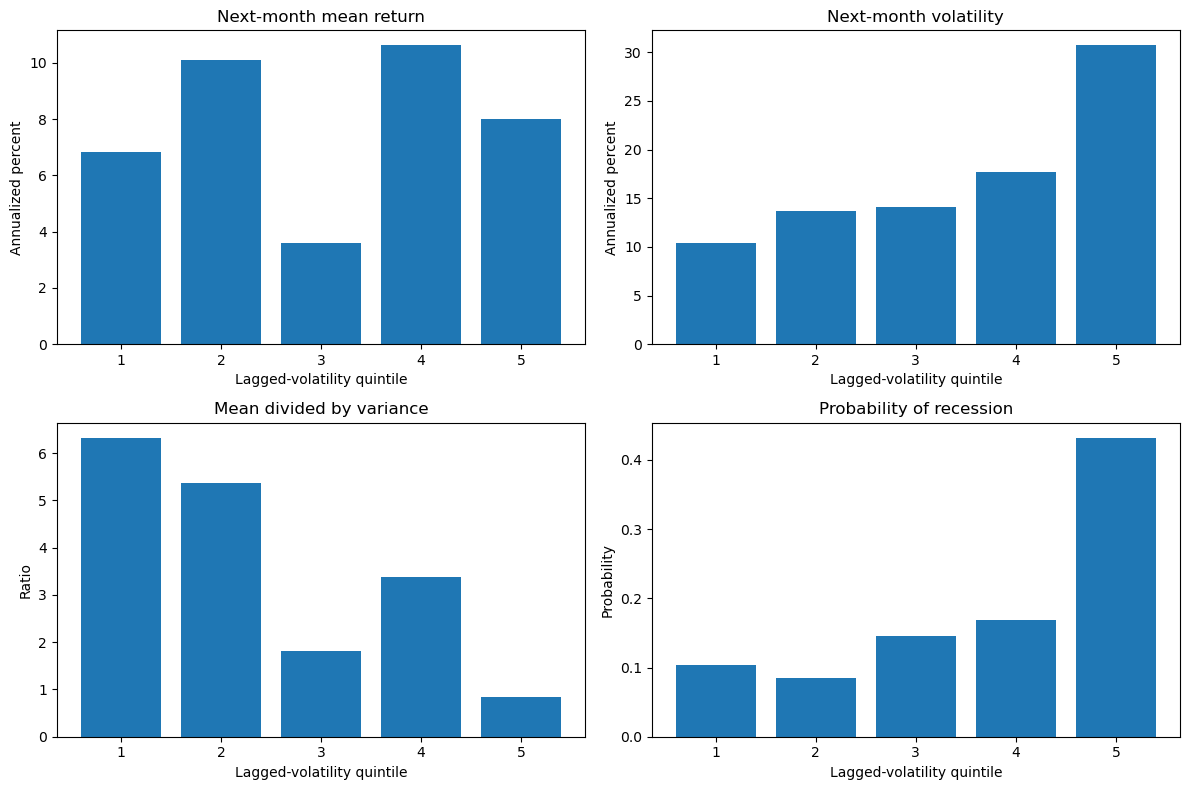

In [3]:
market_sorts = market_volatility_sorts(panel)
display(market_sorts.round(3))
plot_market_volatility_sorts(market_sorts);

## 3. Figure 2: realized volatility and recessions

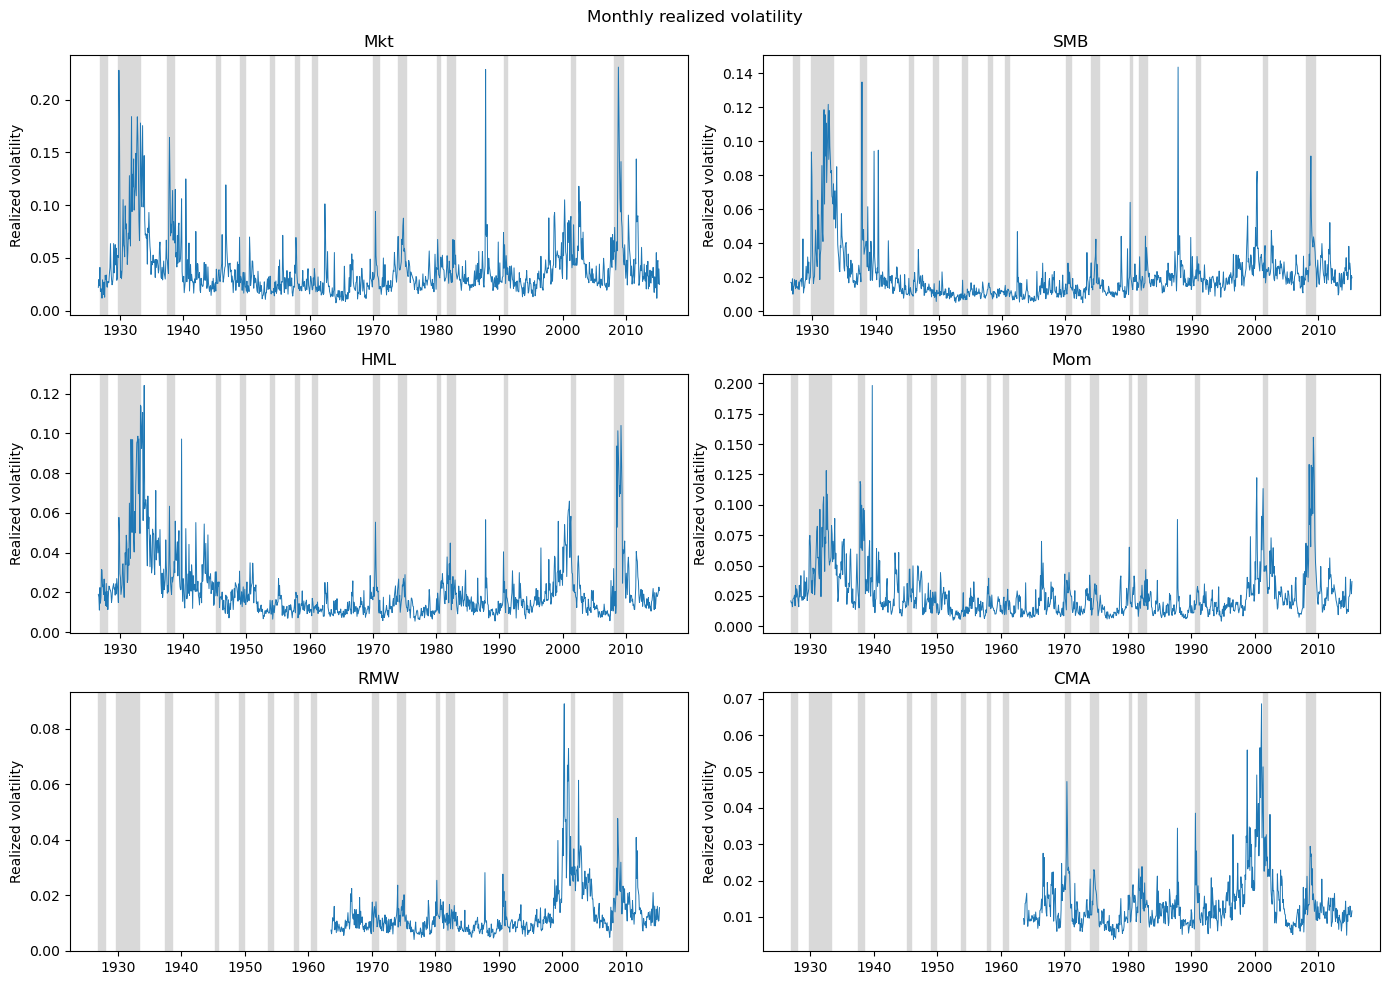

In [4]:
plot_realized_volatility(panel, FACTORS);

## 4. Table I: volatility-managed factor alphas

Panel A controls for the corresponding unmanaged factor. Panel B adds the Fama–French three factors. The FF5 specification is retained below as a clearly labelled project extension.

In [5]:
own_factor = run_spanning_tests(panel, FACTORS, 'Own factor', HAC_LAGS)
ff3 = run_spanning_tests(panel, FACTORS, 'FF3', HAC_LAGS)
table_i = pd.concat([own_factor, ff3], ignore_index=True)
display(table_i[[
    'managed_factor', 'specification', 'alpha_annual_pct',
    'alpha_t_hac12', 'nobs', 'r_squared',
]].round(3))

,managed_factor,specification,alpha_annual_pct,alpha_t_hac12,nobs,r_squared
0,Mkt,Own factor,4.932,2.794,1065,0.361
1,SMB,Own factor,-0.588,-0.449,1065,0.366
2,HML,Own factor,1.727,1.357,1065,0.291
3,Mom,Own factor,12.829,6.238,1060,0.203
4,RMW,Own factor,2.801,2.809,621,0.339
5,CMA,Own factor,0.361,0.654,621,0.452
6,Mkt,FF3,5.631,3.119,1065,0.376
7,SMB,FF3,-0.265,-0.207,1065,0.370
8,HML,FF3,2.452,1.874,1065,0.322
9,Mom,FF3,10.735,5.904,1060,0.236


In [6]:
# Compare replicated and published Panel A point estimates
published_alpha = {'Mkt': 4.86, 'SMB': -0.58, 'HML': 1.97, 'Mom': 12.51, 'RMW': 2.44, 'CMA': 0.38}
published_loading = {'Mkt': 0.61, 'SMB': 0.62, 'HML': 0.57, 'Mom': 0.47, 'RMW': 0.62, 'CMA': 0.68}
factor_keys = {label: factor for factor, label in FACTORS.items()}
comparison = own_factor[['managed_factor', 'alpha_annual_pct', 'nobs']].copy()
comparison['replicated_loading'] = [
    own_factor.loc[index, f"{factor_keys[label]}_loading"]
    for index, label in enumerate(comparison['managed_factor'])
]
comparison['published_alpha_pct'] = comparison['managed_factor'].map(published_alpha)
comparison['alpha_difference_pct'] = comparison['alpha_annual_pct'] - comparison['published_alpha_pct']
comparison['published_loading'] = comparison['managed_factor'].map(published_loading)
comparison['loading_difference'] = comparison['replicated_loading'] - comparison['published_loading']
display(comparison.round(3))

,managed_factor,alpha_annual_pct,nobs,replicated_loading,published_alpha_pct,alpha_difference_pct,published_loading,loading_difference
0,Mkt,4.932,1065,0.601,4.86,0.072,0.61,-0.009
1,SMB,-0.588,1065,0.605,-0.58,-0.008,0.62,-0.015
2,HML,1.727,1065,0.539,1.97,-0.243,0.57,-0.031
3,Mom,12.829,1060,0.450,12.51,0.319,0.47,-0.020
4,RMW,2.801,621,0.583,2.44,0.361,0.62,-0.037
5,CMA,0.361,621,0.672,0.38,-0.019,0.68,-0.008


In [7]:
# Project extension: FF5 spanning alphas
ff5 = run_spanning_tests(panel, FACTORS, 'FF5', HAC_LAGS)
display(ff5[['managed_factor', 'alpha_annual_pct', 'alpha_t_hac12', 'nobs', 'r_squared']].round(3))
TABLES.mkdir(parents=True, exist_ok=True)
pd.concat([table_i, ff5], ignore_index=True).to_csv(SPANNING_TABLE, index=False)

,managed_factor,alpha_annual_pct,alpha_t_hac12,nobs,r_squared
0,Mkt,1.164,0.572,622,0.454
1,SMB,-1.299,-0.681,622,0.488
2,HML,3.814,2.158,622,0.487
3,Mom,12.987,5.462,622,0.295
4,RMW,3.893,3.560,621,0.422
5,CMA,0.865,1.293,621,0.491


## 5. Figure 3: cumulative market performance

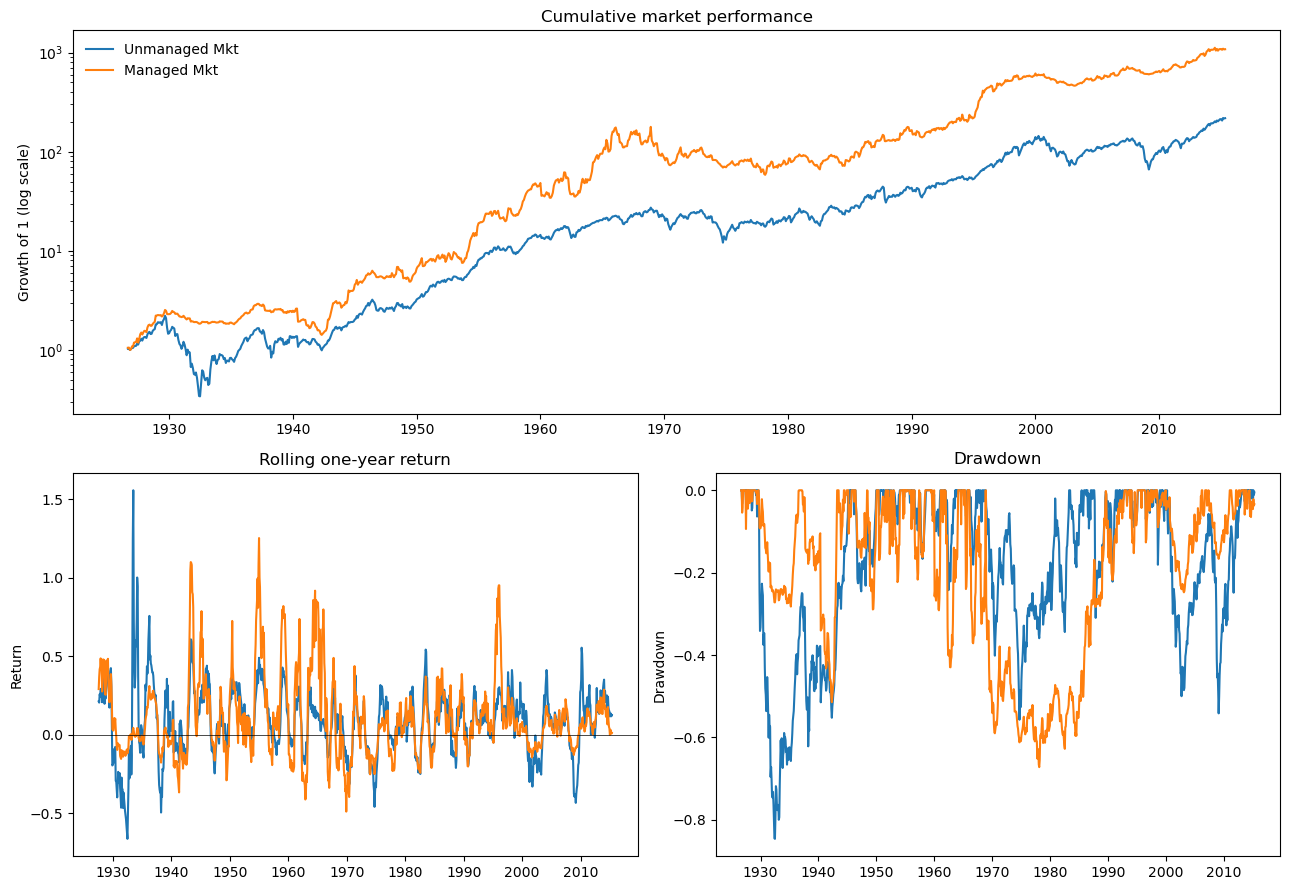

In [8]:
plot_market_cumulative_performance(panel);

## 6. Table II: mean–variance efficient portfolios

For each opportunity set, the factors first form an unconditional in-sample MVE portfolio. The aggregate MVE portfolio is then volatility-timed using its own lagged realized variance.

In [9]:
table_ii, table_ii_weights = replicate_mve_volatility_timing(
    panel, daily, REPLICATION_MVE_SETS, ANALYSIS_END, HAC_LAGS
)
display(table_ii.round(3))
display(table_ii_weights.round(3))
published_table_ii_alpha = {
    'Mkt': 4.86, 'FF3': 4.99, 'FF3 + Mom': 4.04,
    'FF5': 1.34, 'FF5 + Mom': 2.01,
}
table_ii_comparison = table_ii[[
    'opportunity_set', 'alpha_annual_pct', 'original_sharpe',
    'managed_sharpe', 'observations',
]].copy()
table_ii_comparison['published_alpha_pct'] = (
    table_ii_comparison['opportunity_set'].map(published_table_ii_alpha)
)
table_ii_comparison['alpha_difference_pct'] = (
    table_ii_comparison['alpha_annual_pct']
    - table_ii_comparison['published_alpha_pct']
)
display(table_ii_comparison.round(3))
table_ii.to_csv(MVE_TABLE, index=False)

,opportunity_set,observations,start,end,alpha_annual_pct,alpha_t_hac12,r_squared,original_sharpe,managed_sharpe,appraisal_ratio
0,Mkt,1065,1926-08-31,2015-04-30,4.932,2.797,0.361,0.419,0.515,0.330
1,FF3,1065,1926-08-31,2015-04-30,4.539,3.658,0.161,0.521,0.638,0.469
2,FF3 + Mom,1060,1927-01-31,2015-04-30,4.167,5.886,0.232,0.983,1.110,0.727
3,FF5,621,1963-08-31,2015-04-30,1.252,3.399,0.425,1.139,1.118,0.494
4,FF5 + Mom,621,1963-08-31,2015-04-30,1.941,4.125,0.355,1.298,1.341,0.706


,opportunity_set,factor,weight_gross_normalized
0,Mkt,mkt_rf,1.000
1,FF3,mkt_rf,0.345
2,FF3,smb,0.154
3,FF3,hml,0.501
4,FF3 + Mom,mkt_rf,0.194
5,FF3 + Mom,smb,0.070
6,FF3 + Mom,hml,0.350
7,FF3 + Mom,mom,0.386
8,FF5,ff5_mkt_rf,0.156
9,FF5,ff5_smb,0.129


,opportunity_set,alpha_annual_pct,original_sharpe,managed_sharpe,observations,published_alpha_pct,alpha_difference_pct
0,Mkt,4.932,0.419,0.515,1065,4.86,0.072
1,FF3,4.539,0.521,0.638,1065,4.99,-0.451
2,FF3 + Mom,4.167,0.983,1.110,1060,4.04,0.127
3,FF5,1.252,1.139,1.118,621,1.34,-0.088
4,FF5 + Mom,1.941,1.298,1.341,621,2.01,-0.069


## 7. Table III: recession betas

SMB is retained as a transparent extension to the paper's displayed factors. A negative interaction indicates that volatility management reduces factor exposure in recessions.

In [10]:
table_iii = run_recession_beta_tests(panel, FACTORS, HAC_LAGS)
display(table_iii.round(3))
published_table_iii = pd.DataFrame({
    'managed_factor': ['Mkt', 'HML', 'Mom', 'RMW', 'CMA'],
    'published_expansion_beta': [0.83, 0.73, 0.74, 0.63, 0.77],
    'published_recession_change': [-0.51, -0.43, -0.53, -0.08, -0.41],
})
table_iii_comparison = table_iii.merge(
    published_table_iii, on='managed_factor', how='inner',
)
table_iii_comparison['expansion_beta_difference'] = (
    table_iii_comparison['nonrecession_beta']
    - table_iii_comparison['published_expansion_beta']
)
table_iii_comparison['recession_change_difference'] = (
    table_iii_comparison['recession_beta_interaction']
    - table_iii_comparison['published_recession_change']
)
display(table_iii_comparison[[
    'managed_factor', 'nonrecession_beta', 'published_expansion_beta',
    'expansion_beta_difference', 'recession_beta_interaction',
    'published_recession_change', 'recession_change_difference',
]].round(3))

,managed_factor,nonrecession_beta,nonrecession_beta_se_hac12,recession_beta_interaction,recession_beta_interaction_se_hac12,recession_beta,recession_beta_se_hac12,nobs,r_squared
0,Mkt,0.827,0.128,-0.513,0.134,0.313,0.079,1065,0.426
1,SMB,0.633,0.133,-0.151,0.145,0.482,0.099,1065,0.370
2,HML,0.708,0.124,-0.431,0.165,0.277,0.137,1065,0.338
3,Mom,0.725,0.109,-0.533,0.123,0.192,0.067,1060,0.274
4,RMW,0.594,0.195,-0.080,0.216,0.514,0.134,621,0.342
5,CMA,0.763,0.127,-0.401,0.123,0.362,0.055,621,0.481


,managed_factor,nonrecession_beta,published_expansion_beta,expansion_beta_difference,recession_beta_interaction,published_recession_change,recession_change_difference
0,Mkt,0.827,0.83,-0.003,-0.513,-0.51,-0.003
1,HML,0.708,0.73,-0.022,-0.431,-0.43,-0.001
2,Mom,0.725,0.74,-0.015,-0.533,-0.53,-0.003
3,RMW,0.594,0.63,-0.036,-0.080,-0.08,0.000
4,CMA,0.763,0.77,-0.007,-0.401,-0.41,0.009


## 8. Replication assessment

The economically important published patterns are reproduced: volatility-managed market, HML, and especially momentum have positive own-factor alphas; SMB remains the exception; aggregate MVE timing raises Sharpe ratios; and managed-factor exposure falls in recessions. Small point-estimate differences reflect the current French data vintage, the April 2015 endpoint inferred from counts, and available factor definitions. The project uses Newey–West(12) inference for its own analysis, so significance should be compared with the paper only after keeping the paper's heteroskedasticity-only convention separate. This notebook validates the available replication scope; it does not reproduce unavailable holdings, HXZ opportunity sets, or every paper subpanel.